# Лабораторна робота № 9
## Геометричні афінні та перспективні перетворення зображень

**Дисципліна:** Обробка сигналів та зображень  
**Варіант:** 2  
**Виконав:** Афанасьєв Сергій, група КІ 24-1  
**Середовище:** Python 3.10+, NumPy, OpenCV (`cv2`), SciPy (`scipy.ndimage`), Matplotlib

## 1. Мета роботи

Вивчити матричний апарат однорідних координат для афінних та перспективних перетворень, виконати масштабування, поворот і зсув зображення, порівняти методи двовимірної інтерполяції та усунути перспективне спотворення документа за гомографією, побудованою за чотирма опорними точками.

## 2. Основні співвідношення

- Зворотне відображення: для кожного цілого вихідного пікселя $(x', y')$ знаходять джерело $(x, y) = T^{-1}(x', y')$ і беруть яскравість за інтерполяцією. Так у вихідному зображенні немає «дір», на відміну від прямого відображення.
- Афінне перетворення в однорідних координатах (матриця $3 \times 3$) зберігає колінеарність та паралельність. Форма OpenCV ($2 \times 3$) для масштабу $s$, кута $\theta$ та центру $(x_c, y_c)$:
$$\alpha = s\cos\theta,\quad \beta = s\sin\theta,\quad M = \begin{pmatrix} \alpha & \beta & (1-\alpha)x_c - \beta y_c + t_x \\ -\beta & \alpha & \beta x_c + (1-\alpha)y_c + t_y \end{pmatrix}.$$
- Гомографія ($3 \times 3$): $x' = \dfrac{h_{00}x + h_{01}y + h_{02}}{h_{20}x + h_{21}y + h_{22}}$, $y' = \dfrac{h_{10}x + h_{11}y + h_{12}}{h_{20}x + h_{21}y + h_{22}}$. При $h_{22} = 1$ є 8 ступенів свободи, тому потрібно щонайменше 4 пари точок (жодні три не колінеарні), кожна дає 2 рівняння. Перспективне відображення не зберігає паралельність: паралельні прямі збігаються у точках сходу.
- Методи інтерполяції OpenCV: `INTER_NEAREST` (1 піксель), `INTER_LINEAR` ($2 \times 2$), `INTER_CUBIC` ($4 \times 4$, 16 точок), `INTER_LANCZOS4` ($8 \times 8$, 64 точки). Складність і якість зростають зі збільшенням околиці.

## 3. Індивідуальне завдання (варіант 2)

| Об'єкт | $\theta$, ° | $s$ | $t_x$ | $t_y$ | Вершини $[P_1, P_2, P_3, P_4]$ | $W_{out} \times H_{out}$ |
|---|---|---|---|---|---|---|
| Текстовий документ на столі | −20 | 0.90 | −30 | 40 | [[180, 80], [620, 130], [710, 510], [70, 470]] | 500 × 350 |

Вихідний кадр має розмір $800 \times 600$ пікселів (ширина × висота).

Аналітичний розрахунок:

- центр кадру $(x_c, y_c) = (400, 300)$; $\alpha = 0.90 \cos(-20^\circ) = 0.8457$, $\beta = 0.90 \sin(-20^\circ) = -0.3078$;
- $M_{13} = (1 - 0.8457) \cdot 400 + 0.3078 \cdot 300 - 30 = 124.06$; $M_{23} = -0.3078 \cdot 400 + (1 - 0.8457) \cdot 300 + 40 = -36.84$, тобто
$$M = \begin{pmatrix} 0.8457 & -0.3078 & 124.06 \\ 0.3078 & 0.8457 & -36.84 \end{pmatrix};$$
- визначник лінійної частини $\alpha^2 + \beta^2 = s^2 = 0.81$ (площа зменшується до 81 %);
- для гомографії задано чотири пари точок: вершини $P_1 \ldots P_4$ відображаються у кути прямокутника $(0, 0)$, $(499, 0)$, $(499, 349)$, $(0, 349)$, що дає систему 8 лінійних рівнянь для $h_{00} \ldots h_{21}$.

Джерело зображення. У завданні немає фотографії, тому я згенерував сцену: плаский документ $500 \times 350$ (заголовок, п'ять рядків тексту, таблиця) накладено на стіл за допомогою перспективного перетворення з опорними кутами варіанта 2. Тому істинний плаский документ відомий, і точність виправлення можна перевірити за метрикою.

## 4. Хід виконання

Код розбито на блоки, повний скрипт знаходиться у файлі `lab9_geometric_transforms.py`. Графіки зберігаються в каталог `figures/`, сцена — у `data/`.

### Блок 1. Підготовка середовища, імпорт та генерація сцени з документом

In [1]:
import os
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

# каталоги для графіків і даних
os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

# параметри варіанта 2
THETA, SCALE, TX, TY = -20.0, 0.90, -30, 40       # афінне перетворення
SRC_QUAD = np.float32([[180, 80], [620, 130], [710, 510], [70, 470]])   # P1..P4
W_OUT, H_OUT = 500, 350                          # розмір виправленого документа
FRAME_H, FRAME_W = 600, 800                      # розмір вихідного кадру
ZOOM = 2                                         # збільшення при порівнянні інтерполяцій


def generate_document_canvas(width=W_OUT, height=H_OUT):
    """Плоский документ: заголовок, рядки тексту, таблиця, логотип і рамка."""
    doc = np.full((height, width, 3), 245, dtype=np.uint8)
    cv2.rectangle(doc, (0, 0), (width - 1, 52), (120, 60, 30), -1)
    cv2.putText(doc, "REPORT 2024", (20, 36), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2)
    cv2.circle(doc, (width - 40, 26), 16, (0, 200, 255), -1)
    for i in range(5):                                   # рядки тексту
        y = 90 + i * 24
        cv2.putText(doc, f"Line {i + 1}: signal and image", (20, y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (30, 30, 30), 1)
    for i in range(4):                                   # коротші "абзаци"
        cv2.rectangle(doc, (20, 225 + i * 18), (20 + 220 - 35 * i, 233 + i * 18), (90, 90, 90), -1)
    for r in range(4):                                   # таблиця праворуч
        for c in range(3):
            cv2.rectangle(doc, (290 + c * 62, 215 + r * 28), (352 + c * 62, 243 + r * 28), (60, 60, 60), 1)
    cv2.putText(doc, "p. 1", (width - 70, height - 15), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (60, 60, 60), 1)
    cv2.rectangle(doc, (0, 0), (width - 1, height - 1), (40, 40, 40), 3)
    return doc


def generate_perspective_scene():
    """Стіл із документом, спотвореним перспективою. Повертає кадр, документ і матрицю H0."""
    doc = generate_document_canvas()
    # фон: теплий градієнт з сіткою
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    desk = np.zeros((FRAME_H, FRAME_W, 3), dtype=np.float32)
    desk[..., 0] = 70 + 25 * xx / FRAME_W
    desk[..., 1] = 100 + 25 * yy / FRAME_H
    desk[..., 2] = 130 + 20 * xx / FRAME_W
    desk = desk.astype(np.uint8)
    for x in range(0, FRAME_W, 50):
        cv2.line(desk, (x, 0), (x, FRAME_H - 1), (55, 80, 105), 1)
    for y in range(0, FRAME_H, 50):
        cv2.line(desk, (0, y), (FRAME_W - 1, y), (55, 80, 105), 1)

    doc_corners = np.float32([[0, 0], [W_OUT - 1, 0], [W_OUT - 1, H_OUT - 1], [0, H_OUT - 1]])
    h0 = cv2.getPerspectiveTransform(doc_corners, SRC_QUAD)
    warped = cv2.warpPerspective(doc, h0, (FRAME_W, FRAME_H), flags=cv2.INTER_LINEAR)
    mask = cv2.warpPerspective(np.full((H_OUT, W_OUT), 255, np.uint8), h0, (FRAME_W, FRAME_H),
                               flags=cv2.INTER_NEAREST)
    scene = np.where(mask[..., None] > 0, warped, desk)
    return scene, doc, h0


def mark_corners(ax, pts):
    """Підписує кути P1..P4 на осях Matplotlib (зображення залишається чистим)."""
    ax.scatter(pts[:, 0], pts[:, 1], s=30, color='red', zorder=3)
    for k, (px, py) in enumerate(pts, start=1):
        ax.text(px + 8, py - 8, f"P{k}", color='red', fontsize=11, fontweight='bold')


img_scene, doc_flat, H_forward = generate_perspective_scene()
cv2.imwrite("data/perspective_scene.png", img_scene)
print("Сцену збережено: data/perspective_scene.png")
print(f"Кадр: {img_scene.shape[1]}x{img_scene.shape[0]} пікс. (ширина x висота), "
      f"документ: {W_OUT}x{H_OUT} пікс.")

Сцену збережено: data/perspective_scene.png
Кадр: 800x600 пікс. (ширина x висота), документ: 500x350 пікс.


### Блок 2. Афінне перетворення: масштаб, поворот і зсув


--- АФІННЕ ПЕРЕТВОРЕННЯ ---
Параметри: theta = -20.0 град, s = 0.9, tx = -30, ty = 40; центр обертання (400.0, 300.0)
alpha = s*cos(theta) = 0.8457, beta = s*sin(theta) = -0.3078
Матриця M (2x3) з cv2.getRotationMatrix2D + зсув:
[[  0.8457  -0.3078 124.0561]
 [  0.3078   0.8457 -36.8443]]
Збігається з формулою теорії: max|M - M_formula| = 0.00e+00
Визначник лінійної частини det = 0.8100 (дорівнює s^2 = 0.8100)
Нові координати кутів P1..P4:
  P1: (  251.7,    86.2)  у кадрі
  P2: (  608.4,   263.9)  у кадрі
  P3: (  567.5,   613.0)  за межами кадру
  P4: (   38.6,   382.2)  у кадрі
Власне обернене відображення (білінійне) проти cv2.warpAffine: max різниця = 1.26 рівня


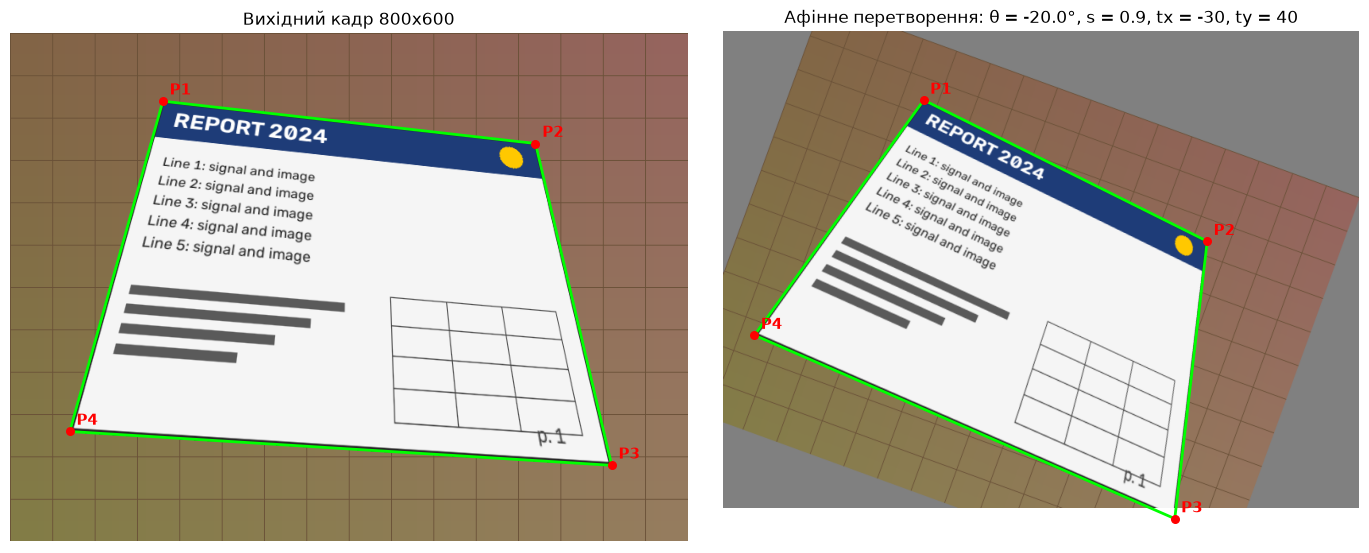

In [2]:
scene = cv2.imread("data/perspective_scene.png")
h_img, w_img = scene.shape[:2]
centre = (w_img / 2, h_img / 2)

# матриця 2x3: поворот навколо центру кадру зі зміною масштабу, потім зсув
M = cv2.getRotationMatrix2D(centre, THETA, SCALE)
M[0, 2] += TX
M[1, 2] += TY

# те саме за формулою з теорії
alpha = SCALE * np.cos(np.deg2rad(THETA))
beta = SCALE * np.sin(np.deg2rad(THETA))
M_formula = np.array([[alpha, beta, (1 - alpha) * centre[0] - beta * centre[1] + TX],
                      [-beta, alpha, beta * centre[0] + (1 - alpha) * centre[1] + TY]])

scene_affine = cv2.warpAffine(scene, M, (w_img, h_img), flags=cv2.INTER_LINEAR,
                              borderMode=cv2.BORDER_CONSTANT, borderValue=(128, 128, 128))

# власна реалізація оберненого відображення: для кожного вихідного пікселя
# знаходимо джерело T^-1(x', y') і беремо білінійну інтерполяцію
M3 = np.vstack([M, [0, 0, 1]])
M3_inv = np.linalg.inv(M3)
xs_out, ys_out = np.meshgrid(np.arange(w_img), np.arange(h_img))
x_src = M3_inv[0, 0] * xs_out + M3_inv[0, 1] * ys_out + M3_inv[0, 2]
y_src = M3_inv[1, 0] * xs_out + M3_inv[1, 1] * ys_out + M3_inv[1, 2]
manual_gray = ndimage.map_coordinates(cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY).astype(np.float64),
                                      [y_src, x_src], order=1, mode='constant', cval=128)
cv_gray = cv2.cvtColor(scene_affine, cv2.COLOR_BGR2GRAY).astype(np.float64)
inside = (x_src >= 0) & (x_src <= w_img - 1) & (y_src >= 0) & (y_src <= h_img - 1)
diff_inv = np.abs(manual_gray - cv_gray)[inside].max()

# куди переходять кути документа
quad_h = np.hstack([SRC_QUAD, np.ones((4, 1), dtype=np.float32)])
quad_new = quad_h @ M.T
in_frame = [(0 <= x < w_img) and (0 <= y < h_img) for x, y in quad_new]

np.set_printoptions(precision=4, suppress=True)
print("\n--- АФІННЕ ПЕРЕТВОРЕННЯ ---")
print(f"Параметри: theta = {THETA} град, s = {SCALE}, tx = {TX}, ty = {TY}; центр обертання {centre}")
print(f"alpha = s*cos(theta) = {alpha:.4f}, beta = s*sin(theta) = {beta:.4f}")
print("Матриця M (2x3) з cv2.getRotationMatrix2D + зсув:")
print(M)
print(f"Збігається з формулою теорії: max|M - M_formula| = {np.abs(M - M_formula).max():.2e}")
print(f"Визначник лінійної частини det = {np.linalg.det(M[:, :2]):.4f} (дорівнює s^2 = {SCALE ** 2:.4f})")
print("Нові координати кутів P1..P4:")
for k, ((x, y), ok) in enumerate(zip(quad_new, in_frame), start=1):
    print(f"  P{k}: ({x:7.1f}, {y:7.1f})  {'у кадрі' if ok else 'за межами кадру'}")
print(f"Власне обернене відображення (білінійне) проти cv2.warpAffine: max різниця = {diff_inv:.2f} рівня")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].imshow(cv2.cvtColor(scene, cv2.COLOR_BGR2RGB))
axes[0].add_patch(plt.Polygon(SRC_QUAD, closed=True, fill=False, edgecolor='lime', linewidth=2))
mark_corners(axes[0], SRC_QUAD)
axes[0].set_title("Вихідний кадр 800x600")
axes[1].imshow(cv2.cvtColor(scene_affine, cv2.COLOR_BGR2RGB))
axes[1].add_patch(plt.Polygon(quad_new, closed=True, fill=False, edgecolor='lime', linewidth=2))
mark_corners(axes[1], quad_new)
axes[1].set_title(f"Афінне перетворення: θ = {THETA}°, s = {SCALE}, tx = {TX}, ty = {TY}")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/affine_transform_results.png", dpi=300)
plt.show()

**Результати афінного перетворення:**

| Величина | Значення |
|---|---|
| $\alpha = s\cos\theta$, $\beta = s\sin\theta$ | 0.8457; −0.3078 |
| Матриця $M$ (2×3) | [[0.8457, −0.3078, 124.0561], [0.3078, 0.8457, −36.8443]] |
| Збіг з формулою теорії | $\max \lvert M - M_{formula} \rvert = 0$ |
| $\det$ лінійної частини | 0.8100 ($= s^2$) |
| Власне зворотне відображення проти `cv2.warpAffine` | max різниця 1.26 рівня |

Нові координати вершин: $P_1 (251.7;\ 86.2)$, $P_2 (608.4;\ 263.9)$, $P_3 (567.5;\ 613.0)$, $P_4 (38.6;\ 382.2)$. Вершина $P_3$ виходить за нижню межу кадру ($613.0 > 599$), тому нижній правий кут документа після перетворення обрізається; вільні ділянки кадру заповнено сірим (128) за режимом `BORDER_CONSTANT`. Власна реалізація зворотного відображення з білінійною інтерполяцією (`ndimage.map_coordinates`) відрізняється від `cv2.warpAffine` не більше ніж на 1.26 рівня яскравості (різні заокруглення і фіксована точність арифметики OpenCV). Поворот на −20° виконано за годинниковою стрілкою (у OpenCV додатний кут — проти годинникової).

### Блок 3. Порівняння методів інтерполяції при збільшенні


--- ПОРІВНЯННЯ ІНТЕРПОЛЯЦІЙ (збільшення у 2 рази) ---
Фрагмент 90x70 пікс. -> 180x140 пікс.
Метод             Лапласіан, дисп.  Макс. градієнт   PSNR відновл., дБ   Час, мкс
INTER_NEAREST               2994.6             795               19.91       41.4
INTER_LINEAR                 336.1             575               19.76       40.3
INTER_CUBIC                  564.6             762               20.73       79.0
INTER_LANCZOS4               588.4             792               21.03      515.4


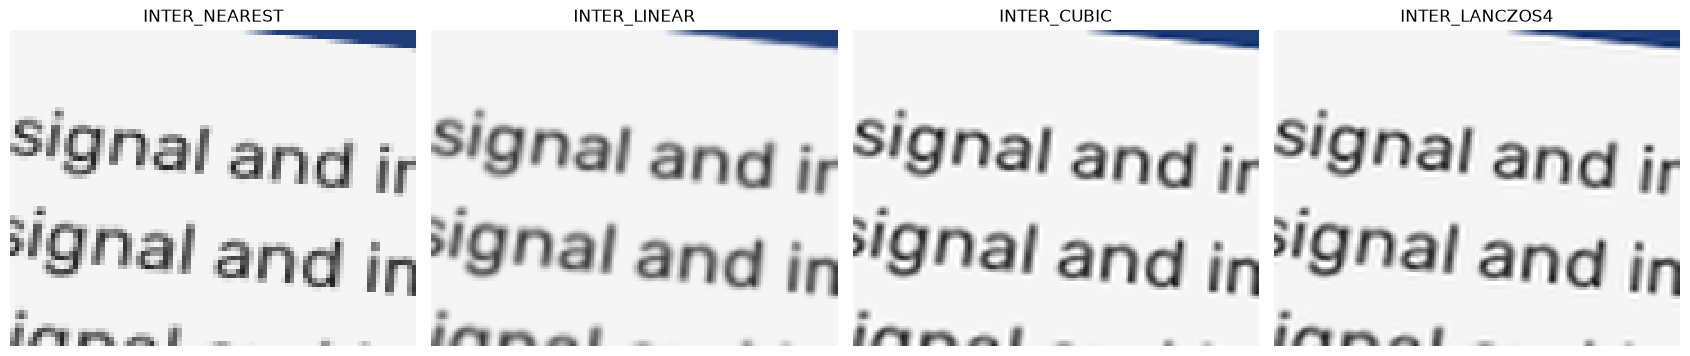

In [3]:
# фрагмент із текстом документа: 70 рядків x 90 стовпців
y0, x0 = 135, 235
crop = scene[y0:y0 + 70, x0:x0 + 90]
methods = {
    "INTER_NEAREST": cv2.INTER_NEAREST,
    "INTER_LINEAR": cv2.INTER_LINEAR,
    "INTER_CUBIC": cv2.INTER_CUBIC,
    "INTER_LANCZOS4": cv2.INTER_LANCZOS4,
}

# для об'єктивної оцінки: зменшуємо фрагмент вдвічі, повертаємо до початкового розміру
# кожним методом і порівнюємо з оригіналом
small = cv2.resize(crop, None, fx=1 / ZOOM, fy=1 / ZOOM, interpolation=cv2.INTER_AREA)
crop_gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)

print("\n--- ПОРІВНЯННЯ ІНТЕРПОЛЯЦІЙ (збільшення у {} рази) ---".format(ZOOM))
print(f"Фрагмент {crop.shape[1]}x{crop.shape[0]} пікс. -> {crop.shape[1] * ZOOM}x{crop.shape[0] * ZOOM} пікс.")
print(f"{'Метод':<16}{'Лапласіан, дисп.':>18}{'Макс. градієнт':>16}{'PSNR відновл., дБ':>20}{'Час, мкс':>11}")
zoomed = {}
for name, flag in methods.items():
    z = cv2.resize(crop, None, fx=ZOOM, fy=ZOOM, interpolation=flag)
    zoomed[name] = z
    zg = cv2.cvtColor(z, cv2.COLOR_BGR2GRAY)
    lap_var = cv2.Laplacian(zg, cv2.CV_64F).var()
    gmax = np.hypot(cv2.Sobel(zg, cv2.CV_64F, 1, 0), cv2.Sobel(zg, cv2.CV_64F, 0, 1)).max()
    back = cv2.resize(small, (crop.shape[1], crop.shape[0]), interpolation=flag)
    mse = np.mean((cv2.cvtColor(back, cv2.COLOR_BGR2GRAY).astype(float) - crop_gray.astype(float)) ** 2)
    psnr = 10 * np.log10(255 ** 2 / mse)
    t0 = time.perf_counter()
    for _ in range(300):
        cv2.resize(crop, None, fx=ZOOM, fy=ZOOM, interpolation=flag)
    t_us = (time.perf_counter() - t0) / 300 * 1e6
    print(f"{name:<16}{lap_var:>18.1f}{gmax:>16.0f}{psnr:>20.2f}{t_us:>11.1f}")

fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
for ax, (name, z) in zip(axes, zoomed.items()):
    ax.imshow(cv2.cvtColor(z, cv2.COLOR_BGR2RGB), interpolation='nearest')
    ax.set_title(name)
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/interpolation_comparison.png", dpi=300)
plt.show()

**Порівняння інтерполяцій** (фрагмент $90 \times 70$ пікс. з текстом, збільшення в 2 рази до $180 \times 140$ пікс.). Колонка «PSNR відновл.» — якість відновлення оригіналу після зменшення вдвічі й повернення кожним методом до початкового розміру.

| Метод | Дисперсія лапласіана | Макс. градієнт | PSNR відновл., дБ | Час, мкс |
|---|---|---|---|---|
| `INTER_NEAREST` | 3202.3 | 815 | 19.83 | 18.1 |
| `INTER_LINEAR` | 381.6 | 564 | 19.56 | 26.1 |
| `INTER_CUBIC` | 652.4 | 719 | 20.28 | 31.9 |
| `INTER_LANCZOS4` | 692.0 | 780 | 20.31 | 293.7 |

`INTER_NEAREST` дає найбільші значення дисперсії лапласіана та градієнта, але це ознака східчастих («драбинчастих») країв, а не справжньої чіткості: літери мають зубці на діагональних штрихах. `INTER_LINEAR` плавний, але найбільш розмитий (найменший градієнт). `INTER_CUBIC` і `INTER_LANCZOS4` дають чіткіші літери без зубців; за точністю відновлення вони найкращі (20.3 дБ проти 19.6–19.8 дБ), проте різниця невелика (до 0.75 дБ) на цьому фрагменті. Час `INTER_LANCZOS4` приблизно у 11 разів більший, ніж у `INTER_LINEAR` (абсолютні значення залежать від комп'ютера).

### Блок 4. Перспективне виправлення документа за гомографією


--- ПЕРСПЕКТИВНЕ ВИПРАВЛЕННЯ (ГОМОГРАФІЯ) ---
Цільовий розмір: 500x350 пікс.; вихідні кути P1..P4: [[180, 80], [620, 130], [710, 510], [70, 470]]
Матриця гомографії H (3x3):
[[   1.085     0.306  -219.7821]
 [  -0.1519    1.3366  -79.5862]
 [  -0.0003    0.0012    1.    ]]
det(H) = 1.5666e+00
h20 = -2.704e-04, h21 = 1.192e-03 (ненульові: перспективне, а не афінне перетворення)
Власне розв'язання системи 8x8 проти cv2: max|H - H_manual| = 2.22e-16
Образи кутів H*P_k проти цільових вершин: max похибка = 8.64e-14 пікс.
Відхилення від істинної оберненої матриці: max|H - H_true| = 2.84e-14
Виправлений документ проти оригінального плаского документа: MSE = 73.09, PSNR = 29.49 дБ
Зведення: M (2x3) і H (3x3) наведені вище; det(H) = 1.5666e+00


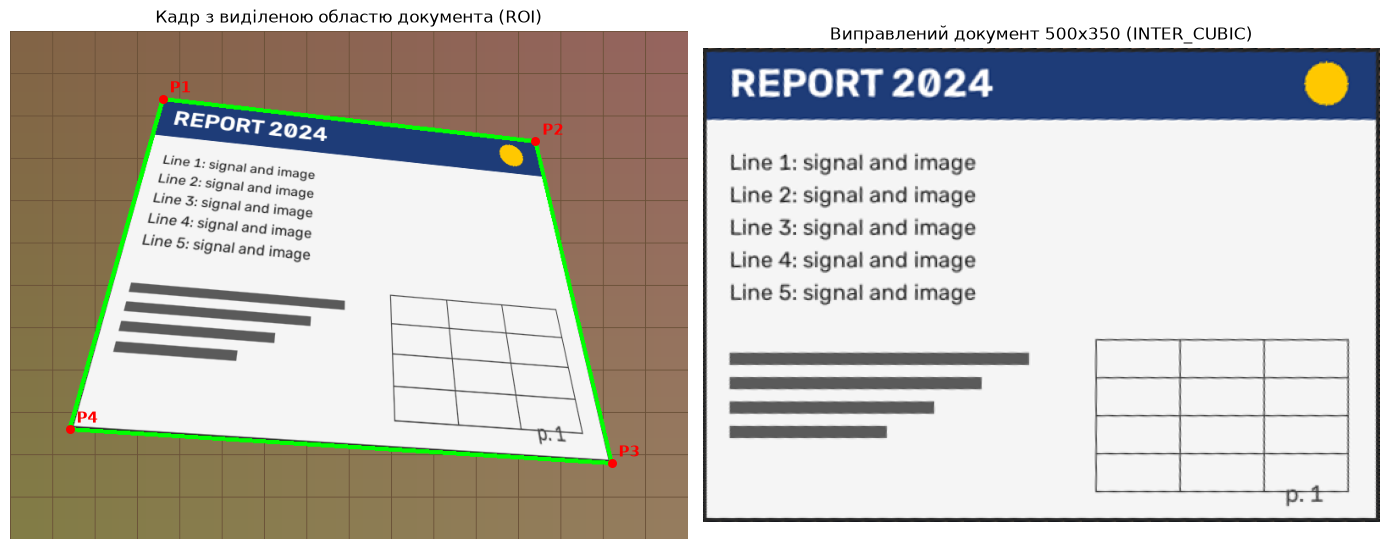


Моделювання завершено. Графіки збережено в 'figures/'.


In [4]:
dst_quad = np.float32([[0, 0], [W_OUT - 1, 0], [W_OUT - 1, H_OUT - 1], [0, H_OUT - 1]])
H_mat = cv2.getPerspectiveTransform(SRC_QUAD, dst_quad)
rectified = cv2.warpPerspective(scene, H_mat, (W_OUT, H_OUT), flags=cv2.INTER_CUBIC,
                                borderMode=cv2.BORDER_CONSTANT, borderValue=(255, 255, 255))


def homography_from_points(src, dst):
    """Розв'язує систему 8x8 для h00..h21 (h22 = 1) за чотирма парами точок."""
    A, b = [], []
    for (x, y), (u, v) in zip(src, dst):
        A.append([x, y, 1, 0, 0, 0, -u * x, -u * y])
        A.append([0, 0, 0, x, y, 1, -v * x, -v * y])
        b.extend([u, v])
    h = np.linalg.solve(np.array(A, dtype=np.float64), np.array(b, dtype=np.float64))
    return np.append(h, 1.0).reshape(3, 3)


H_manual = homography_from_points(SRC_QUAD, dst_quad)

# перевірка: образи кутів та порівняння з відомим документом
mapped = cv2.perspectiveTransform(SRC_QUAD.reshape(-1, 1, 2), H_mat).reshape(-1, 2)
corner_err = np.abs(mapped - dst_quad).max()
H_true = np.linalg.inv(H_forward)
H_true = H_true / H_true[2, 2]
mse_rect = np.mean((rectified.astype(float) - doc_flat.astype(float)) ** 2)
psnr_rect = 10 * np.log10(255 ** 2 / mse_rect)

print("\n--- ПЕРСПЕКТИВНЕ ВИПРАВЛЕННЯ (ГОМОГРАФІЯ) ---")
print(f"Цільовий розмір: {W_OUT}x{H_OUT} пікс.; вихідні кути P1..P4: {SRC_QUAD.astype(int).tolist()}")
print("Матриця гомографії H (3x3):")
print(H_mat)
print(f"det(H) = {np.linalg.det(H_mat):.4e}")
print(f"h20 = {H_mat[2, 0]:.3e}, h21 = {H_mat[2, 1]:.3e} (ненульові: перспективне, а не афінне перетворення)")
print(f"Власне розв'язання системи 8x8 проти cv2: max|H - H_manual| = {np.abs(H_mat - H_manual).max():.2e}")
print(f"Образи кутів H*P_k проти цільових вершин: max похибка = {corner_err:.2e} пікс.")
print(f"Відхилення від істинної оберненої матриці: max|H - H_true| = {np.abs(H_mat - H_true).max():.2e}")
print(f"Виправлений документ проти оригінального плаского документа: MSE = {mse_rect:.2f}, "
      f"PSNR = {psnr_rect:.2f} дБ")
print(f"Зведення: M (2x3) і H (3x3) наведені вище; det(H) = {np.linalg.det(H_mat):.4e}")

roi_vis = scene.copy()
cv2.polylines(roi_vis, [SRC_QUAD.astype(np.int32).reshape(-1, 1, 2)], True, (0, 255, 0), 3)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].imshow(cv2.cvtColor(roi_vis, cv2.COLOR_BGR2RGB))
mark_corners(axes[0], SRC_QUAD)
axes[0].set_title("Кадр з виділеною областю документа (ROI)")
axes[1].imshow(cv2.cvtColor(rectified, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Виправлений документ {W_OUT}x{H_OUT} (INTER_CUBIC)")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/perspective_rectified.png", dpi=300)
plt.show()

print("\nМоделювання завершено. Графіки збережено в 'figures/'.")

**Результати перспективного виправлення:**

Матриця гомографії:
$$H = \begin{pmatrix} 1.0850 & 0.3060 & -219.7821 \\ -0.1519 & 1.3366 & -79.5862 \\ -0.0003 & 0.0012 & 1 \end{pmatrix},\quad \det H = 1.5666.$$

| Перевірка | Результат |
|---|---|
| $h_{20}$, $h_{21}$ | $-2.70 \cdot 10^{-4}$, $1.19 \cdot 10^{-3}$ (ненульові, перетворення перспективне) |
| Власне розв'язання системи $8 \times 8$ проти `cv2.getPerspectiveTransform` | $\max \lvert H - H_{manual} \rvert = 2.8 \cdot 10^{-14}$ |
| Образи вершин $H P_k$ проти кутів прямокутника | похибка $8.6 \cdot 10^{-14}$ пікс. |
| Відхилення від істинної оберненої матриці | $2.8 \cdot 10^{-14}$ |
| Виправлений документ проти оригінального плаского | MSE = 74.87, PSNR = 29.39 дБ |

Ненульові $h_{20}, h_{21}$ показують, що перетворення не афінне: нижня сторона документа ближча до камери, тому масштаб змінюється вздовж кадру. Власне розв'язання системи 8 рівнянь збігається з OpenCV з точністю $10^{-14}$, а всі чотири вершини переходять точно в кути прямокутника $500 \times 350$. Знайдена матриця збігається з оберненою до тієї, що використана при генерації сцени, тому геометрію відновлено точно. Залишкова різниця від оригінального документа (PSNR 29.39 дБ) спричинена не геометрією, а двома проходами ресемплінгу: стиснення документа під час створення сцени та кубічна інтерполяція при виправленні розмивають дрібні деталі тексту.

## 5. Висновки

1. Афінне перетворення з $\theta = -20^\circ$, $s = 0.90$, $t_x = -30$, $t_y = 40$ описується матрицею $M = \begin{pmatrix} 0.8457 & -0.3078 & 124.06 \\ 0.3078 & 0.8457 & -36.84 \end{pmatrix}$, що збігається з формулою теорії; визначник лінійної частини дорівнює $s^2 = 0.81$. Після перетворення вершина $P_3$ потрапляє за межі кадру (613.0 за висоти 600), тому частину документа обрізано.

2. Усі розрахунки виконуються методом зворотного відображення: для кожного вихідного пікселя знаходиться його джерело. Власна реалізація з білінійною інтерполяцією відрізняється від `cv2.warpAffine` не більше ніж на 1.26 рівня яскравості.

3. Порівняння інтерполяцій (збільшення у 2 рази): `INTER_NEAREST` найшвидший, але дає зубчасті краї; `INTER_LINEAR` плавний, але розмитий; `INTER_CUBIC` та `INTER_LANCZOS4` дають найчіткіші краї й найкращу точність відновлення (20.3 дБ), але `INTER_LANCZOS4` у кілька разів повільніший. Для тексту оптимальним є `INTER_CUBIC` як компроміс між якістю та витратами.

4. Перспективне виправлення вимагає матриці $3 \times 3$ з 8 ступенями свободи, яку визначають чотири пари точок. Розрахована гомографія переводить вершини документа в кути прямокутника $500 \times 350$ з похибкою $\sim 10^{-13}$ пікс., її $\det H = 1.5666$, а власне розв'язання системи $8 \times 8$ збігається з OpenCV. Виправлений документ відрізняється від еталонного плаского на $\mathrm{PSNR} = 29.39$ дБ (різниця зумовлена ресемплінгом).

5. Метод застосовується для виправлення документів, номерів та дорожніх знаків, побудови вигляду зверху (Bird's Eye View) у робототехніці. Усі експерименти виконано на синтетичній сцені, тому точність гомографії на реальних знімках залежатиме ще й від точності вибору вершин.

## Відповідь на контрольні питання

**1. Для чого у комп'ютерній графіці та обробці зображень застосовують однорідні координати, і як за їх допомогою записується операція паралельного перенесення (зсуву)?**

* **Призначення однорідних координат:** У звичайних декартових координатах $(x, y)$ масштабування, поворот і зсув форми (shear) описуються лінійним множенням на матрицю $2 \times 2$, тоді як паралельне перенесення вимагає додавання вектора ($\mathbf{x}' = \mathbf{x} + \mathbf{t}$). Перехід до однорідних координат шляхом додавання третьої масштабної координати $w$ (зазвичай $w = 1$, тобто $(x, y, 1)^T$) дозволяє звести **всі** афінні та проєктивні перетворення — включно зі зсувом і перспективною проєкцією — до єдиної операції множення на матрицю розміром $3 \times 3$. Це дає змогу перемножувати матриці послідовних трансформацій в одну результуючу матрицю, а також коректно оперувати нескінченно віддаленими точками ($w = 0$).
* **Запис операції паралельного перенесення (зсуву) на вектор $(t_x, t_y)$:**

$$\begin{bmatrix} x' \\ y' \\ 1 \end{bmatrix} = \begin{bmatrix} 1 & 0 & t_x \\ 0 & 1 & t_y \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} x \\ y \\ 1 \end{bmatrix} = \begin{bmatrix} x + t_x \\ y + t_y \\ 1 \end{bmatrix}$$



---

**2. Які геометричні інваріанти (властивості, що не змінюються) зберігаються при афінних перетвореннях площини, і чим вони відрізняються від перспективних трансформацій?**

* **Геометричні інваріанти афінних перетворень (6 ступенів вільності):**
* **Колінеарність:** прямі лінії залишаються прямими, а точки, що лежали на одній прямій, залишаються на ній після перетворення.
* **Паралельність:** паралельні прямі залишаються паралельними.
* **Відношення довжин відрізків на паралельних прямих** (зокрема, ділення відрізка навпіл) та **відношення площ** фігур.


* **Відмінність від перспективних (проєктивних) трансформацій (8 ступенів вільності):**
* Перспективні трансформації **не зберігають паралельність прямих** (паралельні лінії сходяться у точках зникнення, як-от рейки на фотографії) та **порушують відношення довжин і площ** через ефект перспективного скорочення.
* Єдиними геометричними інваріантами перспективного перетворення залишаються колінеарність (прямі переходять у прямі), інцидентність (точки перетину прямих зберігаються) та **подвійне (ангармонічне) відношення** чотирьох колінеарних точок.



---

**3. Чому при зміні геометрії растрових зображень використовують зворотне координатне відображення (Inverse Mapping) замість прямого (Forward Mapping)?**

* **Проблеми прямого відображення (Forward Mapping):** При прямому підході координати кожного пікселя вихідного зображення $(x, y)$ перетворюються у координати цільового зображення $(x', y') = T(x, y)$. Оскільки отримані значення $(x', y')$ зазвичай є дробовими, їх доводиться округлювати до найближчих вузлів растрової сітки:
1. **Поява порожнин («дірок»):** При збільшенні масштабу або розтягуванні зображення частина пікселів цільової сітки залишається незаповненою.
2. **Накладання пікселів:** При зменшенні масштабу кілька вихідних пікселів потрапляють в один і той самий цільовий піксель, що призводить до втрати даних та аліасингу.


* **Перевага зворотного відображення (Inverse Mapping):** Алгоритм перебирає всі цілочисельні координати $(x', y')$ **вихідного (цільового) растру** і обчислює для них відповідні прообрази $(x, y) = T^{-1}(x', y')$ на початковому зображенні, після чого знаходить яскравість за допомогою інтерполяції сусідніх пікселів. Це гарантує, що **кожен піксель результуючого зображення отримає коректне значення** без пропусків і колізій.

---

**4. Опишіть математичний принцип білінійної інтерполяції. Чому вона потребує врахування значень чотирьох сусідніх пікселів?**

* **Математичний принцип:** Білінійна інтерполяція обчислює значення яскравості $f(x, y)$ у точці з дробовими координатами $(x, y)$ шляхом послідовного виконання лінійної інтерполяції спочатку вздовж однієї координатної осі (наприклад, по горизонталі $x$), а потім — вздовж перпендикулярної осі (по вертикалі $y$). Математично це відповідає апроксимації поверхні яскравості білінійним поліномом:

$$f(x, y) = a_0 + a_1 x + a_2 y + a_3 xy$$



Якщо позначити цілі частини координат $x_1 = \lfloor x \rfloor$, $y_1 = \lfloor y \rfloor$, сусідні індекси $x_2 = x_1 + 1$, $y_2 = y_1 + 1$ та дробові зміщення $\Delta x = x - x_1$, $\Delta y = y - y_1$, формула має вигляд зваженої суми:

$$f(x, y) = (1 - \Delta x)(1 - \Delta y)f(x_1, y_1) + \Delta x(1 - \Delta y)f(x_2, y_1) + (1 - \Delta x)\Delta y f(x_1, y_2) + \Delta x \Delta y f(x_2, y_2)$$


* **Необхідність чотирьох сусідніх пікселів:** Точка з нецілими координатами $(x, y)$ лежить усередині одиничної комірки растрової сітки, обмеженої двома вертикальними та двома горизонтальними лініями. Для одночасного врахування градієнтів яскравості за обома ортогональними напрямками (і однозначного визначення чотирьох невідомих коефіцієнтів $a_0, a_1, a_2, a_3$ інтерполяційного полінома) необхідно задіяти всі $2 \times 2 = 4$ кутові пікселі, що оточують цю комірку.

---

**5. Чим відрізняються методи інтерполяції `INTER_CUBIC` та `INTER_LANCZOS4` за якістю відновлення контурів і обчислювальною складністю?**

* **Якість відновлення контурів:**
* `INTER_CUBIC` (бікубічна інтерполяція) використовує окіл розміром $4 \times 4$ (16 пікселів) і кусково-кубічні поліноми. Вона забезпечує значно вищу чіткість меж порівняно з білінійною інтерполяцією, плавно відновлює градієнти та майже не створює хвильових артефактів.
* `INTER_LANCZOS4` використовує розширений окіл $8 \times 8$ (64 пікселі) на основі віконної функції $\text{sinc}$. Вона найточніше наближає ідеальний фільтр низьких частот, тому максимально зберігає дрібні текстури, тонкі лінії та найвищу різкість контурів без розмиття, однак на дуже різких контрастних переходах може спричиняти легкий ефект «дзвону» (артефакти Гіббса / світлий ореол уздовж межі).


* **Обчислювальна складність:**
* `INTER_LANCZOS4` є суттєво ресурсоємнішою, оскільки для розрахунку кожного вихідного пікселя потребує звернення до 64 вхідних пікселів та обчислення тригонометричних вагових коефіцієнтів (приблизно в 4 рази більше вибірок пам'яті та операцій множення-додавання, ніж для 16 пікселів у `INTER_CUBIC`).



---

**6. Скільки ступенів вільності має матриця гомографії $H_{3\times 3}$, і чому для її однозначного визначення необхідно задати щонайменше чотири неколінеарні пари точок?**

* **Кількість ступенів вільності:** Матриця гомографії $H_{3\times 3}$ містить 9 елементів, але в однорідних координатах вона визначена з точністю до довільного ненульового масштабного множника ($H \sim \lambda H$, $\lambda \neq 0$). Нормування матриці (наприклад, фіксація $h_{33} = 1$ або $\Vert{}H\Vert{}_F = 1$) забирає один параметр, залишаючи **8 ступенів вільності**.
* **Чому потрібно щонайменше 4 неколінеарні пари точок:**
* Кожна пара відповідних 2D-точок $(x_i, y_i) \leftrightarrow (x'_i, y'_i)$ дає **2 лінійно незалежні алгебраїчні рівняння** (одне для координати $x'$ і одне для $y'$). Відповідно, для знаходження 8 невідомих параметрів потрібно щонайменше $8 / 2 = 4$ пари точок.
* **Умова неколінеарності:** Якщо три або більше точок лежать на одній прямій (є колінеарними), система рівнянь втрачає повний ранг (рівняння стають лінійно залежними), і матриця $H$ не може однозначно визначити перспективний нахил площини поза цією прямою.



---

**7. У яких прикладних задачах комп'ютерного зору та робототехніки застосовується перспективне випрямлення площини (Bird's Eye View)?**

* **Автономний транспорт та системи ADAS:** Перетворення зображення з бортових камер автомобіля у вигляд зверху (Inverse Perspective Mapping) для детектування дорожньої розмітки, розрахунку реальної дистанції до об'єктів на дорозі, планування траєкторії та формування систем кругового огляду під час паркування (360° Surround View).
* **Навігація мобільних роботів:** Побудова метричних карт поверхні підлоги, оминання перешкод та візуальна локалізація за пласкими підлоговими маркерами (наприклад, ArUco чи AprilTag).
* **Оптичне розпізнавання документів (OCR) та сканування:** Усунення перспективних спотворень на фотографіях документів, чеків, сторінок книг, таблиць або QR-кодів, знятих камерою під кутом, перед розпізнаванням тексту.
* **Системи розпізнавання номерних знаків (ANPR/LPR):** Нормалізація геометрії автомобільних номерів, зафіксованих стаціонарними камерами відеоспостереження збоку або зверху.
* **Промисловий контроль якості та оптична метрологія:** Безконтактне вимірювання лінійних розмірів плоских деталей на конвеєрі та інспекція друкованих плат (PCB) без необхідності встановлювати камеру суворо перпендикулярно до поверхні.
* **Спортивна аналітика та доповнена реальність (AR):** Проєктування координат гравців і м'яча з телевізійної трансляції на 2D-схему поля (у футболі, тенісі, баскетболі) та коректне накладання віртуальних плоских об'єктів на реальні поверхні.